# Agrigine 2026–2028: every layer, pre-run

Every layer in the app, predicted for every county and every day of 2026, 2027 and 2028, and written into the app's
own file formats so the date dial simply keeps going past 2025.

**Why pre-run instead of a hosted model.** Every prediction starts from the same point, the last day of data
(December 31, 2025), so each one is the same no matter who asks. Computing them once and serving files is instant
and free; a hosted model would recompute identical numbers on every request. When new 2026 data arrives, this
notebook re-runs on a schedule and the files are republished.

**Which method, for which layer.** The two model notebooks found what works years ahead, and that's what's used:

| Method | Used for | Evidence |
|---|---|---|
| Winning model from `Agrigine_Forecasts.ipynb` | Yields, peak and average greenness | Beat the place average on 2016–2025 |
| Fading from Dec 31, 2025 to normal | Drought, soil moisture, water balance, recent rain and every other daily measure | Measured fade rates, and a test below against starting from normal |
| The county's typical season | Season weather, freeze dates, storms, insurance payouts | Nothing beat the place average years ahead |
| Recent values | Acres, irrigated share | Change slowly year to year |
| Unchanged | Soil properties | Don't change |

Run after `Agrigine_Forecasts.ipynb` and `Agrigine_Daily_Predictions.ipynb`. Kernel: *Agrigine model (sklearn 1.6.1)*.

In [1]:
import json, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
APP = REPO / 'agrigine' / 'public' / 'data'
OBSERVED = list(range(2000, 2026))
FUTURE = [2026, 2027, 2028]
ORIGIN = pd.Timestamp('2025-12-31')
MISSING = -32768
B62 = '0123456789abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ'

bundle = json.loads((APP / 'agrigine.json').read_text())
COUNTIES = bundle['counties']
NC = len(COUNTIES)
ORDER = [c['f'] for c in COUNTIES]
didx = json.loads((APP / 'daily' / 'index.json').read_text())
CH, SCALE = didx['channels'], np.array(didx['scale'], np.float32)
print(f'{NC} counties · daily channels: {", ".join(CH)}')

253 counties · daily channels: tmax, tmin, pcpn, rain7, rain30, dry, vpd, et0, srad, wind, rh, wb30, soil


## 1. Daily measures: fade from December 31, 2025 to normal

For each daily measure, each county's normal for every date (2000–2025, smoothed over a week either side), and how
fast a departure from normal fades, measured from the data: the correlation between today's departure and the one
L days later. A predicted day is its normal plus the December 31, 2025 departure times that fade. Soil moisture and
30-day rain remember for weeks; a single day's high or rain barely at all, so those are just normal.

In [2]:
t0 = time.time()
DATES = pd.date_range('2000-01-01', '2025-12-31')
X = np.full((len(CH), NC, len(DATES)), np.nan, np.float32)
pos = 0
for y in OBSERVED:
    n = 366 if y % 4 == 0 else 365
    a = np.fromfile(APP / 'daily' / f'{y}.bin', dtype='<i2').reshape(len(CH), NC, n).astype(np.float32)
    X[:, :, pos:pos + n] = np.where(a == MISSING, np.nan, a / SCALE[:, None, None])
    pos += n
slot_of = lambda dates: ((dates.map(lambda d: pd.Timestamp(2000, d.month, d.day)) - pd.Timestamp(2000, 1, 1)).days).to_numpy()
SLOT = slot_of(DATES)

# Normal for each channel, county and calendar slot, then smoothed over 15 days around the year
NORMAL = np.full((len(CH), NC, 366), np.nan, np.float32)
for s in range(366):
    NORMAL[:, :, s] = np.nanmean(X[:, :, SLOT == s], axis=2)
pad = np.concatenate([NORMAL[:, :, -7:], NORMAL, NORMAL[:, :, :7]], axis=2)
NORMAL = np.stack([np.nanmean(pad[:, :, s:s + 15], axis=2) for s in range(366)], axis=2)

ANOM = X - NORMAL[:, :, SLOT]
LAGS = 400
def fade(a):
    # Correlation between a departure and the one L days later, pooled over counties; cut to 0 once it stops mattering.
    a = a - np.nanmean(a)
    var = np.nanmean(a * a)
    r = np.array([1.0] + [np.nanmean(a[:, :-L] * a[:, L:]) / var for L in range(1, LAGS)])
    r = np.minimum.accumulate(np.clip(r, 0, 1))
    r[np.argmax(r < 0.05):] = 0 if (r < 0.05).any() else r[np.argmax(r < 0.05):]
    return r
FADE = np.stack([fade(ANOM[j]) for j in range(len(CH))])
half = {CH[j]: int(np.argmax(FADE[j] < 0.5)) for j in range(len(CH))}
print(f'Normals and fade rates in {time.time() - t0:.0f} s. Days until half a departure has faded: {half}')

Normals and fade rates in 14 s. Days until half a departure has faded: {'tmax': 2, 'tmin': 2, 'pcpn': 1, 'rain7': 4, 'rain30': 17, 'dry': 17, 'vpd': 3, 'et0': 2, 'srad': 1, 'wind': 1, 'rh': 2, 'wb30': 19, 'soil': 107}


In [3]:
# Does starting from the Dec 31 conditions beat starting from normal? Origins Dec 31 of 2015–2024, the next 365 days.
rows = []
for oy in range(2015, 2025):
    o = DATES.get_loc(pd.Timestamp(oy, 12, 31))
    span = np.arange(o + 1, min(o + 366, len(DATES)))
    L = span - o
    for j, ch in enumerate(CH):
        truth = X[j][:, span]
        clim = NORMAL[j][:, SLOT[span]]
        faded = clim + ANOM[j][:, [o]] * FADE[j][np.minimum(L, LAGS - 1)]
        for lo, hi, label in ((1, 30, 'days 1–30'), (31, 90, 'days 31–90'), (91, 365, 'days 91–365')):
            m = (L >= lo) & (L <= hi)
            rows.append({'channel': ch, 'lead': label, 'normal': np.nanmean(np.abs(truth[:, m] - clim[:, m])),
                         'faded': np.nanmean(np.abs(truth[:, m] - faded[:, m]))})
test = pd.DataFrame(rows).groupby(['channel', 'lead'])[['normal', 'faded']].mean()
test['gain'] = (1 - test.faded / test.normal).map('{:+.0%}'.format)
test.unstack('lead')['gain'][['days 1–30', 'days 31–90', 'days 91–365']]

lead,days 1–30,days 31–90,days 91–365
channel,,,
dry,+23%,+1%,+0%
et0,+3%,+0%,-0%
pcpn,+0%,+0%,+0%
rain30,+28%,-0%,+0%
rain7,+6%,-0%,-0%
rh,+4%,+1%,+0%
soil,+69%,+39%,+8%
srad,+0%,+0%,-0%
tmax,+1%,-0%,+0%


In [4]:
# Write daily/2026.bin – 2028.bin in the app's layout: [channel][county][day of year]
o = len(DATES) - 1
LOWER = {'pcpn': 0, 'rain7': 0, 'rain30': 0, 'dry': 0, 'vpd': 0, 'et0': 0, 'srad': 0, 'wind': 0, 'rh': 0, 'soil': 0}
UPPER = {'rh': 100, 'soil': 100}
for y in FUTURE:
    days = pd.date_range(f'{y}-01-01', f'{y}-12-31')
    L = (days - ORIGIN).days.to_numpy()
    out = np.empty((len(CH), NC, len(days)), np.float32)
    for j, ch in enumerate(CH):
        v = NORMAL[j][:, slot_of(days)] + np.nan_to_num(ANOM[j][:, [o]]) * FADE[j][np.minimum(L, LAGS - 1)]
        out[j] = np.clip(v, LOWER.get(ch, -np.inf), UPPER.get(ch, np.inf))
    packed = np.where(np.isfinite(out), np.clip(np.round(out * SCALE[:, None, None]), -32767, 32767), MISSING).astype('<i2')
    packed.tofile(APP / 'daily' / f'{y}.bin')
didx['years'] = OBSERVED + FUTURE
didx['predicted'] = {'from': '2026-01-01', 'origin': '2025-12-31', 'method': 'normal for the date plus the 2025-12-31 departure, faded at the measured rate'}
(APP / 'daily' / 'index.json').write_text(json.dumps(didx))
print('Wrote daily', FUTURE)

Wrote daily [2026, 2027, 2028]


## 2. Drought: the weekly map and the chance of severe drought

The weekly Drought Monitor intensity (DSCI) fades from its December 30, 2025 value to each county's normal for that
week of the year, at the rate measured from 26 years of maps. The drought level shown is the one most often seen
historically at that intensity. The daily chance of severe drought within 4 and 8 weeks fades the same way, from the
last prediction of 2025 to the county's usual rate for that month.

In [5]:
W0 = pd.Timestamp('2000-01-04')
NW = bundle['nWeeks']
cat = np.array([[int(c['wkc'][2 * w]) for w in range(NW)] for c in COUNTIES]).T                               # [week, county]
dsci = np.array([[B62.index(c['wkc'][2 * w + 1]) / 61 * 500 for w in range(NW)] for c in COUNTIES]).T
wk_dates = W0 + pd.to_timedelta(np.arange(NW) * 7, 'D')
woy = np.minimum((wk_dates.dayofyear.to_numpy() - 1) // 7, 51)
dsci_norm = np.stack([dsci[woy == w].mean(axis=0) for w in range(52)])                                          # [52, county]
a = dsci - dsci_norm[woy]
r_w = np.array([1.0] + [np.mean(a[:-L] * a[L:]) / np.mean(a * a) for L in range(1, 160)])
r_w = np.minimum.accumulate(np.clip(r_w, 0, 1))
# The drought level most often seen at each intensity
level_at = np.array([np.bincount(cat[(dsci >= b) & (dsci < b + 10)].ravel(), minlength=6).argmax() if ((dsci >= b) & (dsci < b + 10)).any() else 0
                     for b in range(0, 510, 10)])
future_weeks = pd.date_range(wk_dates[-1] + pd.Timedelta(days=7), '2028-12-31', freq='7D')
Lw = np.arange(1, len(future_weeks) + 1)
fw_woy = np.minimum((future_weeks.dayofyear.to_numpy() - 1) // 7, 51)
f_dsci = np.clip(dsci_norm[fw_woy] + a[-1] * r_w[np.minimum(Lw, 159)][:, None], 0, 500)
f_cat = level_at[np.minimum((f_dsci // 10).astype(int), 50)]
WKC_FUTURE = [''.join(f'{f_cat[w, c]}{B62[int(round(f_dsci[w, c] / 500 * 61))]}' for w in range(len(future_weeks))) for c in range(NC)]
print(f'{len(future_weeks)} predicted weekly maps; half of a DSCI departure fades in {int(np.argmax(r_w < 0.5))} weeks')

# Chance of severe drought within 4 and 8 weeks: usual rate for the county and month, and the fade from Dec 31
pidx = json.loads((APP / 'predict' / 'index.json').read_text())
PCH = pidx['channels']
p2025 = np.fromfile(APP / 'predict' / '2025.bin', dtype='<i2').reshape(len(PCH), NC, 365).astype(np.float32)
p2025 = np.where(p2025 == MISSING, np.nan, p2025 / 10)
flag = cat >= 3                                                                                                 # D2 or worse on >1% of the county
months = wk_dates.month.to_numpy()
def usual(weeks):
    lab = np.stack([flag[j + 1:j + 1 + weeks].any(axis=0) for j in range(NW - weeks)]).astype(np.float32)
    return np.stack([lab[months[:NW - weeks] == m].mean(axis=0) * 100 for m in range(1, 13)]), lab
CHANCE = {}
for weeks, ch in ((4, 'drought_4w'), (8, 'drought_8w')):
    base, lab = usual(weeks)
    la = lab - lab.mean(axis=0)
    r_p = np.array([1.0] + [np.mean(la[:-L] * la[L:]) / np.mean(la * la) for L in range(1, 160)])
    CHANCE[ch] = (base, np.minimum.accumulate(np.clip(r_p, 0, 1)), p2025[PCH.index(ch), :, -1] - base[11])

156 predicted weekly maps; half of a DSCI departure fades in 30 weeks


## 3. Season layers: yields, weather, drought, freeze, storms, insurance, satellite

One set of values per county, crop and season, appended to the app's own series so every season layer, chart and
profile reads 2026–2028 like any other year. Yields carry the status **p** (predicted) instead of **r** (reported).

In [6]:
fc = pd.read_csv(REPO / 'notebooks' / 'forecasts' / 'forecasts_2026_2028.csv', dtype={'fips': str})
YIELD_TARGET = {'C': 'yield_corn', 'S': 'yield_soybeans', 'W': 'yield_wheat', 'G': 'yield_sorghum'}
fcv = {(r.target, r.fips, r.year): r.forecast for r in fc.itertuples()}
fcm = {(r.target, r.year): r.model for r in fc.itertuples()}
CROP_INDEX = {'C': 0, 'S': 1, 'W': 2, 'G': 3}
WINDOWS = {'C': (5, 1, 9, 30, False), 'S': (5, 1, 10, 31, False), 'G': (6, 1, 10, 31, False), 'W': (9, 1, 6, 30, True)}
DAY0 = pd.Timestamp('2000-01-01')
I_RECENT = [OBSERVED.index(y) for y in range(2016, 2026)]

def vals(a):
    return np.array([np.nan if v is None else v for v in a], float)
def mean_of(a, idx=None):
    v = vals(a) if idx is None else vals(a)[idx]
    return None if np.isnan(v).all() else round(float(np.nanmean(v)), 2)
def median_of(a):
    v = vals(a)
    return None if np.isnan(v).all() else round(float(np.nanmedian(v)))
def last_of(a):
    v = vals(a)[::-1]
    v = v[~np.isnan(v)]
    return None if not len(v) else round(float(v[0]), 3)
def recent_mean(a, n=3):
    v = vals(a); v = v[~np.isnan(v)][-n:]
    return None if not len(v) else round(float(v.mean()))
def trailing_trend(y, st, year):
    pts = [(OBSERVED[i], y[i]) for i in range(len(y)) if st[i] == 'r' and y[i] is not None and OBSERVED[i] >= year - 15]
    if len(pts) < 6:
        return None
    b, a0 = np.polyfit(*zip(*pts), 1)
    return float(b * year + a0)

future = {}
for c in COUNTIES:
    f = c['f']; rec = {'d': {}}
    for k, d in c['d'].items():
        ys = [fcv.get((YIELD_TARGET[k], f, y)) for y in FUTURE]
        ys = [None if v is None or np.isnan(v) else round(float(v), 1) for v in ys]
        # When the winning forecast is itself a trend line, the season is expected on trend (0%) and that forecast is
        # its trend; otherwise the forecast is compared with the county's recent trend.
        on_trend = [fcm.get((YIELD_TARGET[k], y)) == 'county_trend' for y in FUTURE]
        trends = [v if flat and v is not None else trailing_trend(d['y'], d['st'], y) for v, flat, y in zip(ys, on_trend, FUTURE)]
        rec['d'][k] = {
            'y': ys, 'st': ''.join('p' if v is not None else '-' for v in ys),
            'a': [None if v is None or t is None else round((v / t - 1) * 100, 1) for v, t in zip(ys, trends)],
            'trend': [None if t is None else round(t, 1) for t in trends],
            'ap': [recent_mean(d['ap'])] * 3, 'ah': [recent_mean(d['ah'])] * 3,
            **{fld: [mean_of(d[fld])] * 3 for fld in ('pr', 'tv', 'ht', 'gd', 'wk', 'ds')},
            'pa': [0] * 3, 'sv': [median_of(d['sv'])] * 3,
        }
    if c.get('ir'):
        rec['ir'] = {k: {fld: [last_of(v[fld])] * 3 for fld in ('sh', 'yi', 'yn')} for k, v in c['ir'].items()}
    if c.get('md'):
        md_ = c['md']
        nx = [fcv.get(('ndvi_max', f, y)) for y in FUTURE]
        rec['md'] = {'nm': [mean_of(md_['nm'])] * 3, 'nx': [None if v is None else round(float(v), 3) for v in nx],
                     'em': [mean_of(md_['em'])] * 3, 'na': [0] * 3, 'pk': [median_of(md_['pk'])] * 3}
        ev = [fcv.get(('evi_mean', f, y)) for y in FUTURE]
        if all(v is not None for v in ev):
            rec['md']['em'] = [round(float(v), 3) for v in ev]
    if c.get('mp'):
        mp, mx = np.array(vals(c['mp'])).reshape(26, 12), np.array(vals(c['mx'])).reshape(26, 12)
        rec['mp'] = [round(float(v)) for v in np.nanmean(mp, axis=0)] * 3
        rec['mx'] = [round(float(v), 1) for v in np.nanmean(mx, axis=0)] * 3
    if c.get('sw'):
        rec['sw'] = {k: {fld: [mean_of(v[fld])] * 3 for fld in ('hn', 'fh', 'dry', 'hr')} for k, v in c['sw'].items()}
    if c.get('fz'):
        rec['fz'] = {'ls': [median_of(c['fz']['ls'])] * 3, 'ff': [median_of(c['fz']['ff'])] * 3, 'sr': [mean_of(c['fz']['sr'])] * 3}
    # Storms: the county's average count by type, and crop damage, per crop season
    rec['stm'] = {}
    for k in c['d']:
        sm, sd, em, ed, before = WINDOWS[k]
        per = []
        for y in OBSERVED:
            lo = (pd.Timestamp(y - 1 if before else y, sm, sd) - DAY0).days; hi = (pd.Timestamp(y, em, ed) - DAY0).days
            sel = [e for e in c.get('ev', []) if lo <= e[0] <= hi]
            per.append([sum(e[1] == t for e in sel) for t in range(5)] + [sum(e[3] for e in sel)])
        rec['stm'][k] = [round(float(v), 2) for v in np.mean(per, axis=0)]
    # Insurance: average payouts by cause, and by month of loss, over the last ten crop years
    ins, insm = [], []
    for k in c['d']:
        ci = CROP_INDEX[k]
        for g in range(8):
            usd = sum(r[3] for r in c.get('ins', []) if r[1] == ci and r[2] == g and r[0] in I_RECENT) / len(I_RECENT)
            if usd >= 1:
                ins += [[26 + h, ci, g, round(usd)] for h in range(3)]
        for m in range(1, 13):
            usd = sum(r[3] for r in c.get('insm', []) if r[0] == ci and r[2] == m and r[1] in I_RECENT) / len(I_RECENT)
            if usd >= 1:
                insm += [[ci, 26 + h, m, round(usd)] for h in range(3)]
    rec['ins'], rec['insm'] = ins, insm
    rec['wkc'] = WKC_FUTURE[ORDER.index(f)]
    future[f] = rec

out = {'origin': '2025-12-31', 'years': FUTURE, 'weekStart': str(future_weeks[0].date()), 'nWeeks': len(future_weeks), 'counties': future}
(APP / 'predict' / 'future.json').write_text(json.dumps(out, separators=(',', ':')))
print(f'Wrote predict/future.json: {(APP / "predict" / "future.json").stat().st_size / 1e6:.2f} MB')

Wrote predict/future.json: 0.97 MB


## 4. Daily prediction channels for 2026–2028

Same layout as the in-season predictions: each day carries its season's expected yield against trend, and the
chance of severe drought within 4 and 8 weeks.

In [7]:
def season_span(k, s):
    a, b = (pd.Timestamp(s - 1, 9, 1), pd.Timestamp(s, 8, 31)) if k == 'W' else (pd.Timestamp(s, 1, 1), pd.Timestamp(s, 12, 31))
    return a, b

trend_ext = {k: [list(v) for v in pidx['trend'][k]] for k in pidx['trend']}
for y in FUTURE:
    days = pd.date_range(f'{y}-01-01', f'{y}-12-31')
    arr = np.full((len(PCH), NC, len(days)), np.nan, np.float32)
    for k in ('C', 'S', 'W', 'G'):
        ch = PCH.index(f'yield_{k}')
        for ci, c in enumerate(COUNTIES):
            fut = future[c['f']]['d'].get(k)
            if not fut:
                continue
            for s in (y, y + 1):
                if s not in FUTURE:
                    continue
                a, b = season_span(k, s)
                m = (days >= a) & (days <= b)
                v = fut['a'][FUTURE.index(s)]
                if v is not None:
                    arr[ch, ci, m] = v
    L = (days - ORIGIN).days.to_numpy()
    for ch, (base, r_p, dep) in CHANCE.items():
        arr[PCH.index(ch)] = np.clip(base[days.month.to_numpy() - 1].T + dep[:, None] * r_p[np.minimum(L // 7, 159)][None], 0, 100)
    packed = np.where(np.isfinite(arr), np.clip(np.round(arr * 10), -32767, 32767), MISSING).astype('<i2')
    packed.tofile(APP / 'predict' / f'{y}.bin')

for k in trend_ext:
    for ci, c in enumerate(COUNTIES):
        fut = future[c['f']]['d'].get(k)
        trend_ext[k][ci] = trend_ext[k][ci][:26] + (fut['trend'] if fut else [None] * 3)
pidx['years'] = OBSERVED + FUTURE
pidx['trend'] = trend_ext
pidx['predicted'] = {'from': '2026-01-01', 'origin': '2025-12-31'}
(APP / 'predict' / 'index.json').write_text(json.dumps(pidx, separators=(',', ':')))
print('Wrote predict', FUTURE, 'and updated predict/index.json')

Wrote predict [2026, 2027, 2028] and updated predict/index.json


## 5. Every layer, and how 2026–2028 is predicted

In [8]:
LAYERS = [
    ('Crops', 'Yield, yield vs trend', 'Winning model (county trend; gradient boosting or neural network for sorghum)'),
    ('Crops', 'Expected yield this season (by day)', 'The season\'s predicted yield vs trend, on every day of it'),
    ('Crops', 'Harvested acres, production', 'Average of the last three reported seasons × predicted yield'),
    ('Crops', 'Insurance payouts (per acre, total, drought, main cause, this month)', 'Average of 2016–2025 by cause and month'),
    ('Drought', 'Drought level and intensity this week', 'Faded from Dec 30, 2025 to normal for the week'),
    ('Drought', 'Chance of severe drought in 4 / 8 weeks', 'Faded from the last 2025 prediction to the usual rate for the month'),
    ('Drought', 'Worst level, weeks in D2+, intensity (season)', 'Typical season (2000–2025)'),
    ('Drought', 'Water balance, soil moisture (and vs normal)', 'Faded from Dec 31, 2025 to normal for the date'),
    ('Weather', 'Daily high and low, rain, VPD, crop water demand, sunlight, wind, humidity', 'Faded from Dec 31, 2025 to normal for the date'),
    ('Weather', 'Season rain, temperature, heat days, GDD, hot nights, dry spells, heavy rain', 'Typical season (2000–2025)'),
    ('Weather', 'Last spring and first fall freeze, frost-free days, frost risk', 'Typical dates (median) and each date\'s historical risk'),
    ('Storms', 'Damaging storms, hail, wind, tornadoes, floods, crop damage', 'Average season (2000–2025)'),
    ('Land & water', 'Soil water storage, drought-prone soil, productivity', 'Unchanged'),
    ('Land & water', 'Irrigated share', 'Latest reported value'),
    ('Satellite', 'Peak and average greenness', 'Winning model (gradient boosting)'),
    ('Satellite', 'Greenness vs normal, peak date', 'Typical season'),
]
pd.DataFrame(LAYERS, columns=['Category', 'Layers', 'How 2026–2028 is predicted']).set_index('Category')

,Layers,How 2026–2028 is predicted
Category,,
Crops,"Yield, yield vs trend",Winning model (county trend; gradient boosting...
Crops,Expected yield this season (by day),"The season's predicted yield vs trend, on ever..."
Crops,"Harvested acres, production",Average of the last three reported seasons × p...
Crops,"Insurance payouts (per acre, total, drought, m...",Average of 2016–2025 by cause and month
Drought,Drought level and intensity this week,"Faded from Dec 30, 2025 to normal for the week"
Drought,Chance of severe drought in 4 / 8 weeks,Faded from the last 2025 prediction to the usu...
Drought,"Worst level, weeks in D2+, intensity (season)",Typical season (2000–2025)
Drought,"Water balance, soil moisture (and vs normal)","Faded from Dec 31, 2025 to normal for the date"
Weather,"Daily high and low, rain, VPD, crop water dema...","Faded from Dec 31, 2025 to normal for the date"


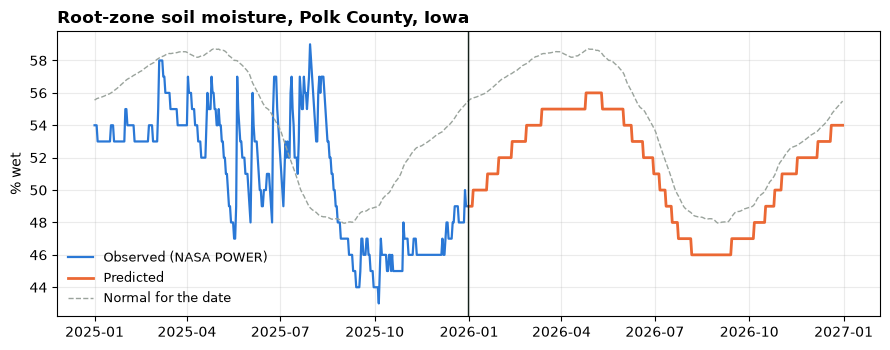

In [9]:
# Polk County, Iowa: soil moisture through 2025 and the predicted fade into 2026
pc = ORDER.index('19153'); j = CH.index('soil')
f26 = np.fromfile(APP / 'daily' / '2026.bin', dtype='<i2').reshape(len(CH), NC, 365)[j, pc] / SCALE[j]
fig, ax = plt.subplots(figsize=(9, 3.6))
recent = DATES >= pd.Timestamp('2025-01-01')
ax.plot(DATES[recent], X[j, pc, recent], color='#2A78D6', lw=1.6, label='Observed (NASA POWER)')
ax.plot(pd.date_range('2026-01-01', '2026-12-31'), f26, color='#EB6834', lw=2, label='Predicted')
ax.plot(pd.date_range('2025-01-01', '2026-12-31'), NORMAL[j, pc, slot_of(pd.date_range('2025-01-01', '2026-12-31'))], color='#9AA39C', lw=1, ls='--', label='Normal for the date')
ax.axvline(ORIGIN, color='#14201A', lw=1)
ax.set_title('Root-zone soil moisture, Polk County, Iowa', loc='left', fontsize=12, fontweight='bold'); ax.set_ylabel('% wet')
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25); plt.tight_layout(); plt.show()